# Hito 1 — Baseline de recuperación

Sistema de verificación de hechos sobre mitología griega, romana y nórdica.

En este notebook se construyen y evalúan los dos baselines de recuperación dispersa, **TF-IDF con similitud coseno** y **BM25**, sobre el corpus del proyecto, siguiendo lo trabajado en el notebook *Text Vectorization I*.

Los pasos pesados se hacen con scripts de `src/` y aquí solo se cargan sus resultados:

| Script | Qué hace |
|---|---|
| `construye_corpus.py` | Junta las 4 fuentes y las trocea en fragmentos (280 palabras, 15 % de solape) |
| `preprocesado.py` | Preprocesado con spaCy de todos los fragmentos |
| `genera_queries.py`, `crea_queries.py` | Queries de evaluación generadas con un LLM y revisadas a mano |

Estructura del notebook:

1. **Corpus y preprocesado**: el corpus, el preprocesado con spaCy, los N-gramas y la frecuencia documental de los términos.
2. **Recuperación**: cómo se construyen los dos sistemas y cómo se pasa de fragmentos a documentos.
3. **Elección del preprocesado**: qué variantes (N-gramas, filtros por frecuencia documental) funcionan mejor.
4. **Evaluación del baseline**: Recall@5, Recall@10 y MRR, en total, por fuente y según el origen de la query.
5. **Análisis de errores**: queries en las que fallan los dos métodos y parámetros de BM25.
6. **Conclusiones**.

In [67]:
import json
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path('..')
DATOS = RAIZ / 'data'
sys.path.append(str(RAIZ / 'src'))   # para importar el preprocesado de las queries

def leer_jsonl(ruta):
    with open(ruta, encoding='utf-8') as f:
        return [json.loads(linea) for linea in f]

# Fragmentos (sin el texto, que no hace falta aquí) y sus tokens ya preprocesados
chunks = pd.DataFrame(leer_jsonl(DATOS / 'processed' / 'chunks.jsonl'))
chunks = chunks[['chunk_id', 'doc_id', 'fuente', 'titulo', 'tipo_fuente', 'n_palabras']]
tokens = leer_jsonl(DATOS / 'processed' / 'chunks_tokens.jsonl')
assert [t['chunk_id'] for t in tokens] == chunks['chunk_id'].tolist()
corpus = [t['tokens'] for t in tokens]

queries = leer_jsonl(DATOS / 'queries.jsonl')
relevant = [set(q['relevant_ids']) for q in queries]

titulo_de_doc = chunks.drop_duplicates('doc_id').set_index('doc_id')['titulo']
doc_de_fila = chunks['doc_id'].values
fila_de_chunk = {cid: i for i, cid in enumerate(chunks['chunk_id'])}

print(f"{chunks['doc_id'].nunique()} documentos, {len(chunks)} fragmentos, {len(queries)} queries")

5727 documentos, 24021 fragmentos, 95 queries


## 1. Corpus y preprocesado

### 1.1. El corpus

Cada documento (un artículo, un libro de la *Ilíada*, una fábula de Ovidio, un vídeo…) se divide en fragmentos de unas 280 palabras con un 15 % de solape. **El fragmento es la unidad que se indexa**; la evaluación se hace a nivel de documento.

In [68]:
resumen = chunks.groupby('fuente').agg(documentos=('doc_id', 'nunique'),
                                       fragmentos=('chunk_id', 'size'),
                                       palabras_por_fragmento=('n_palabras', 'mean'))
resumen['% fragmentos'] = 100 * resumen['fragmentos'] / resumen['fragmentos'].sum()
resumen['tokens_por_fragmento'] = pd.Series([len(t) for t in corpus]).groupby(chunks['fuente']).mean()
print(resumen.round(1).to_string())

           documentos  fragmentos  palabras_por_fragmento  % fragmentos  tokens_por_fragmento
fuente                                                                                       
clasicos          365        3383                   263.5          14.1                 109.9
whe               206        1428                   251.6           5.9                 117.5
wikipedia        4923       16470                   228.7          68.6                 114.1
youtube           233        2740                   188.7          11.4                  81.6


Wikipedia aporta el 69 % de los fragmentos, así que dominará cualquier resultado global; por eso las queries se generaron con un número fijo por fuente y los resultados se darán también por fuente. Los fragmentos de YouTube son más cortos y se quedan con menos tokens tras el preprocesado: el lenguaje oral tiene más palabras vacías.

### 1.2. Preprocesado con spaCy

El preprocesado (`src/preprocesado.py`) sigue la función `prepare_data` del notebook *Text Vectorization I*:

1. Se quitan URLs y se expanden las contracciones
2. spaCy (`en_core_web_sm`, sin parser ni NER) con `nlp.pipe`
3. Se quedan los lemas en minúsculas de los tokens alfabéticos cuya categoría es NOUN, VERB, ADJ o PROPN y que no son stopwords (las de spaCy y unas pocas del dominio, como *video*, *subscribe* o *chapter*)

Con dos cambios pensados para los nombres propios:
- Se quitan tildes y diéresis (*Jörmungandr* → *jormungandr*), porque cada fuente lo escribe de una manera
- Al texto de cada fragmento se le pone delante el título del documento, porque muchos fragmentos de un artículo no repiten el nombre del personaje

In [69]:
i = chunks.index[chunks['fuente'] == 'clasicos'][0]
print(chunks.loc[i, 'titulo'])
print(corpus[i][:40])

# Comprobación: los nombres de las tres mitologías (y sus equivalencias) sobreviven
frecuencia = Counter(w for doc in corpus for w in doc)
nombres = ['zeus', 'jupiter', 'jove', 'hera', 'juno', 'athena', 'minerva', 'odin', 'thor', 'loki', 'jormungandr']
print({n: frecuencia[n] for n in nombres})

Iliad, Book I
['iliad', 'quarrel', 'agamemnon', 'achilles', 'achilles', 'withdraw', 'war', 'send', 'mother', 'thetis', 'ask', 'jove', 'help', 'trojans', 'scene', 'jove', 'juno', 'olympus', 'sing', 'goddess', 'anger', 'achilles', 'son', 'peleus', 'bring', 'countless', 'ill', 'achaeans', 'brave', 'soul', 'send', 'hurrying', 'hades', 'hero', 'yield', 'prey', 'dog', 'vulture', 'counsel', 'jove']
{'zeus': 7596, 'jupiter': 1674, 'jove': 1031, 'hera': 2193, 'juno': 1058, 'athena': 3071, 'minerva': 870, 'odin': 3117, 'thor': 2876, 'loki': 2494, 'jormungandr': 176}


Los nombres de las tres mitologías sobreviven al preprocesado, también las variantes romanas. Las traducciones clásicas del corpus (Butler para Homero, Riley para Ovidio, Bulfinch) usan los nombres romanos: en la *Ilíada* Zeus aparece como *Jove*. Un método léxico no sabe que *zeus* y *jove* son el mismo dios, así que una query con el nombre griego no encontrará esos fragmentos. Es una de las limitaciones que se esperan de los baselines.

### 1.3. Detección de N-gramas

Como en el notebook, con `Phrases` de Gensim. El modelo de N-gramas es parte del preprocesado: si se usa, las queries tienen que pasar por el mismo modelo.

In [70]:
from gensim.models.phrases import Phrases

phrase_model = Phrases(corpus, min_count=2, threshold=20)
corpus_ng = [phrase_model[doc] for doc in corpus]

# N-gramas más frecuentes que se han formado
ngramas = Counter(w for doc in corpus_ng for w in doc if '_' in w)
print(f"{len(ngramas)} N-gramas distintos")
print(ngramas.most_common(40))

38717 N-gramas distintos
[('ancient_greek', 4549), ('greek_mythology', 3891), ('old_norse', 1545), ('trojan_war', 1542), ('fall_love', 791), ('norse_mythology', 765), ('century_bce', 623), ('prose_edda', 618), ('give_birth', 602), ('take_place', 579), ('century_ad', 495), ('poetic_edda', 482), ('bear_american', 446), ('young_man', 408), ('old_english', 364), ('version_myth', 345), ('homer_iliad', 338), ('indo_european', 331), ('ancient_greece', 320), ('snorri_sturluson', 309), ('version_story', 303), ('century_ce', 302), ('epic_poem', 286), ('mount_olympus', 285), ('bronze_age', 282), ('late_century', 279), ('fifth_century', 265), ('right_hand', 264), ('half_brother', 259), ('golden_fleece', 256), ('hesiod_theogony', 250), ('norse_myth', 246), ('son_atreus', 245), ('homer_odyssey', 244), ('roman_empire', 244), ('ovid_metamorphoses', 241), ('mortal_man', 236), ('roman_religion', 230), ('date_century', 229), ('second_century', 227)]


Muchos N-gramas son útiles (*trojan_war*, *golden_fleece*, *prose_edda*, *mount_olympus*), pero hay dos problemas:

- **Ruido**: *bear_american* sale de las listas de personas de Wikipedia, del tipo "(born 1970), American actress", con *born* lematizado como *bear*.
- **Se pierden unigramas**: `Phrases` sustituye las dos palabras por el N-grama. Si un fragmento tiene *homer_iliad* y la query dice solo "Iliad", no coinciden.

Si conviene usarlos o no se decide en la sección 3, midiendo su efecto en la recuperación.

### 1.4. Frecuencia documental de los términos

Como en el ejercicio 8 del notebook: en cuántos fragmentos aparece cada término (sin N-gramas). Además, cuántos términos quitaría cada umbral de `filter_extremes`: `no_below` quita los que aparecen en menos de ese número de fragmentos y `no_above` los que aparecen en más de esa proporción.

Términos distintos: 96812

Más comunes:
    token  nfragmentos    %
      god         8969 37.3
    greek         8368 34.8
      son         7975 33.2
  ancient         6512 27.1
mythology         6333 26.4
      man         6270 26.1
     king         6259 26.1
      say         6057 25.2
     come         5862 24.4
     know         5802 24.2
     give         5760 24.0
     time         5625 23.4
     call         5118 21.3
   father         5110 21.3
 daughter         5059 21.1

Ejemplos de términos que aparecen en un solo fragmento:
['hertyr', 'ploutodoteare', 'ferger', 'αθθιδα', 'retiro', 'mccann', 'kohlruss', 'jailbreak', 'gonnos', 'bottiaei', 'monstrum', 'enheduanna', 'skalda', 'harnessing', 'eurusternos', 'adrestia', 'immortel', 'ηρακλειδαι', 'commutation', 'генис']

Términos que quitaría cada umbral:
      umbral  términos que quita
  no_below=2               46562
  no_below=4               68228
no_above=0.5                   0
no_above=0.1                  80


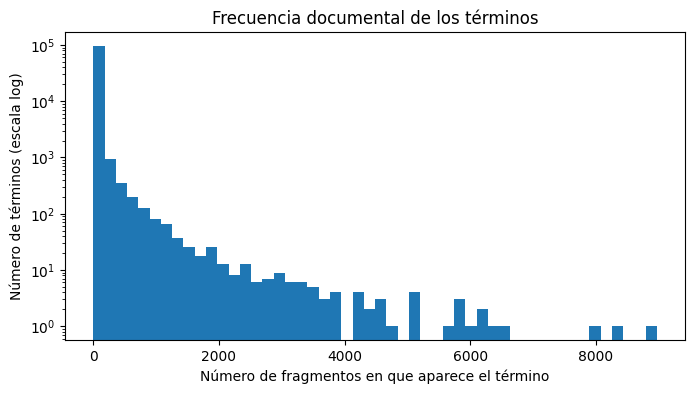

In [71]:
from gensim.corpora import Dictionary

D_completo = Dictionary(corpus)
N = len(corpus)
df_tokens = pd.DataFrame([(D_completo[tid], n) for tid, n in D_completo.dfs.items()],
                         columns=['token', 'nfragmentos'])
df_tokens = df_tokens.sort_values('nfragmentos', ascending=False).reset_index(drop=True)
df_tokens['%'] = 100 * df_tokens['nfragmentos'] / N

print(f"Términos distintos: {len(D_completo)}")
print('\nMás comunes:')
print(df_tokens.head(15).round(1).to_string(index=False))
print('\nEjemplos de términos que aparecen en un solo fragmento:')
print(df_tokens[df_tokens['nfragmentos'] == 1].sample(20, random_state=0)['token'].tolist())

print('\nTérminos que quitaría cada umbral:')
umbrales = [(f'no_below={nb}', (df_tokens['nfragmentos'] < nb).sum()) for nb in [2, 4]]
umbrales += [(f'no_above={na}', (df_tokens['nfragmentos'] > na * N).sum()) for na in [0.5, 0.1]]
print(pd.DataFrame(umbrales, columns=['umbral', 'términos que quita']).to_string(index=False))

plt.figure(figsize=(8, 4))
plt.hist(df_tokens['nfragmentos'], bins=50, log=True)
plt.xlabel('Número de fragmentos en que aparece el término')
plt.ylabel('Número de términos (escala log)')
plt.title('Frecuencia documental de los términos')
plt.show()

Casi la mitad de los términos (46.562 de 96.812) aparecen en un solo fragmento, y con `no_below=4`, el valor del notebook, se quitaría el 70 % del vocabulario (68.228 términos). Muchos son basura: palabras en alfabeto griego o cirílico, términos latinos, errores de los subtítulos automáticos. Pero también hay nombres raros (*enheduanna*, *adrestia*, *bottiaei*), y en una búsqueda *known-item* un nombre raro es justo lo que mejor identifica un documento.

Por arriba, el término más frecuente (*god*) está en el 37 % de los fragmentos, así que `no_above=0.5` no quita nada y `no_above=0.1` solo quita 80 términos, las palabras más habituales del dominio (*god*, *greek*, *son*, *king*…).

Qué umbrales usar se decide en la sección 3, midiendo su efecto en la recuperación en lugar de fijarlos a ojo.

## 2. Recuperación

### 2.1. Preprocesado de las queries

Las queries pasan **exactamente por el mismo preprocesado** que los fragmentos: la misma función `preparar` de `src/preprocesado.py` (sin el título delante, claro) y, si se usan, el mismo modelo de N-gramas. Después, el mismo diccionario: los términos que no están en él se ignoran.

In [72]:
from preprocesado import preparar

q_lemas = preparar([q['query'] for q in queries])     # spaCy una sola vez
q_ng = [phrase_model[t] for t in q_lemas]             # versión con N-gramas

for q, t in list(zip(queries, q_lemas))[:5]:
    print(q['qid'], q['query'])
    print('     ->', t)

q002 What is the origin of the name "Opuntii" in ancient Greek mythology?
     -> ['origin', 'opuntii', 'ancient', 'greek', 'mythology']
q003 What does Plutarch's account of Pan's death have to do with Jesus Christ and early Christianity?
     -> ['plutarch', 'account', 'pan', 'death', 'jesus', 'christ', 'early', 'christianity']
q004 Locrian town listed in Homer's catalogue of ships, named for its thick woods and later renamed
     -> ['locrian', 'town', 'list', 'homer', 'catalogue', 'ship', 'name', 'thick', 'wood', 'rename']
q005 Cupid and Psyche mythological artwork by Bouguereau explained
     -> ['cupid', 'psyche', 'mythological', 'artwork', 'bouguereau', 'explain']
q007 What happens to Odysseus after Homer's Odyssey ends and he meets a new love interest?
     -> ['happen', 'odysseus', 'homer', 'odyssey', 'end', 'meet', 'new', 'love', 'interest']


### 2.2. De fragmentos a documentos

Se indexan fragmentos, pero se evalúa a nivel de documento. Para cada query se recuperan los 200 fragmentos más parecidos y se pasan a documentos: **cada documento puntúa con su mejor fragmento** y aparece una sola vez. Como los fragmentos ya vienen ordenados de mayor a menor puntuación, basta con quedarse con la primera aparición de cada documento.

In [73]:
N_FRAGMENTOS = 200

def a_documentos(filas, k):
    docs, vistos = [], set()
    for fila in filas:
        d = doc_de_fila[fila]
        if d not in vistos:
            vistos.add(d)
            docs.append(d)
            if len(docs) == k:
                break
    return docs

### 2.3. Los dos sistemas

Para poder comparar variantes del preprocesado, la construcción de los índices va en una función que recibe los tokens de los fragmentos y los umbrales del filtro por frecuencia documental. Los dos métodos usan **el mismo diccionario filtrado**, así que ven exactamente los mismos términos.

- **TF-IDF con similitud coseno**, con Gensim como en el ejercicio 11 del notebook. Variante por defecto de `TfidfModel`: frecuencia del término sin transformar, IDF $\log_2(N/df)$ calculado sobre los fragmentos y vectores normalizados, de modo que la similitud coseno es un producto escalar.
- **BM25**, con la librería `bm25s` como en el notebook. Variante de Lucene (la que usa `bm25s` por defecto), con $k_1 = 1.5$ y $b = 0.75$.

In [74]:
from gensim.models import TfidfModel
from gensim.similarities import SparseMatrixSimilarity
import bm25s

K1, B = 1.5, 0.75

def en_diccionario(docs, dic):
    return [[w for w in doc if w in dic.token2id] for doc in docs]

def indexar_bm25(docs, k1=K1, b=B):
    modelo = bm25s.BM25(k1=k1, b=b)
    modelo.index(docs, show_progress=False)
    return modelo

def construir_sistema(docs, no_below, no_above):
    dic = Dictionary(docs)
    dic.filter_extremes(no_below=no_below, no_above=no_above, keep_n=None)
    docs_f = en_diccionario(docs, dic)
    bow = [dic.doc2bow(d) for d in docs_f]
    tfidf = TfidfModel(bow)
    return {'dic': dic,
            'docs': docs_f,
            'tfidf': tfidf,
            'index': SparseMatrixSimilarity(tfidf[bow], num_features=len(dic)),
            'bm25': indexar_bm25(docs_f)}

def retrieve_tfidf(tokens, sistema, k=10):
    tokens = [w for w in tokens if w in sistema['dic'].token2id]
    if not tokens:
        return []
    sims = sistema['index'][sistema['tfidf'][sistema['dic'].doc2bow(tokens)]]
    return a_documentos(np.argsort(-sims)[:N_FRAGMENTOS], k)

def retrieve_bm25(tokens, sistema, k=10, modelo=None):
    modelo = modelo if modelo is not None else sistema['bm25']
    tokens = [w for w in tokens if w in sistema['dic'].token2id]
    if not tokens:
        return []
    filas, _ = modelo.retrieve([tokens], k=N_FRAGMENTOS, show_progress=False)
    return a_documentos(filas[0], k)

## 3. Elección del preprocesado

### 3.1. Métricas

Como en el ejercicio 12 del notebook, pero sobre documentos. Cada query tiene un único documento relevante, así que:

- **Recall@K**: proporción de queries cuyo documento relevante está entre los $K$ primeros.
- **MRR**: media de $1/\text{posición}$ del documento relevante (0 si no está entre los 10 primeros, es decir, MRR@10).

In [75]:
K = 10

def posicion(ranking, rel):
    return next((i for i, d in enumerate(ranking, 1) if d in rel), None)

def recall_at_k(rankings, relevant, k=10):
    return np.mean([len(set(r[:k]) & rel) / len(rel) for r, rel in zip(rankings, relevant)])

def mrr(rankings, relevant):
    return np.mean([1 / p if (p := posicion(r, rel)) else 0 for r, rel in zip(rankings, relevant)])

def metricas(rankings, relevant):
    return {'Recall@5': recall_at_k(rankings, relevant, 5),
            'Recall@10': recall_at_k(rankings, relevant, 10),
            'MRR': mrr(rankings, relevant)}

def buscar_todas(sistema, q_tokens, k=K):
    return ([retrieve_tfidf(t, sistema, k) for t in q_tokens],
            [retrieve_bm25(t, sistema, k) for t in q_tokens])

### 3.2. Variantes

Se repite toda la recuperación combinando tres decisiones del preprocesado:

- **N-gramas**: sí o no.
- **`no_below`**: 1 (no se quita nada por abajo), 2 (se quitan los términos de un solo fragmento) o 4 (el valor del notebook).
- **`no_above`**: 0,5 (en este corpus no quita nada) o 0,1 (quita las palabras que aparecen en más del 10 % de los fragmentos).

Las variantes se comparan con las mismas queries con las que luego se evalúa. No es un ajuste fino de parámetros, sino una elección entre pocas opciones, pero hay que tenerlo en cuenta: el resultado final puede ser algo optimista.

In [76]:
%%time
variantes = []
for ngramas in [False, True]:
    docs, q_tokens = (corpus_ng, q_ng) if ngramas else (corpus, q_lemas)
    for no_below in [1, 2, 4]:
        for no_above in [0.5, 0.1]:
            sistema = construir_sistema(docs, no_below, no_above)
            r_tfidf, r_bm25 = buscar_todas(sistema, q_tokens)
            base = {'N-gramas': 'sí' if ngramas else 'no', 'no_below': no_below,
                    'no_above': no_above, 'términos': len(sistema['dic'])}
            variantes.append({**base, 'método': 'TF-IDF', **metricas(r_tfidf, relevant)})
            variantes.append({**base, 'método': 'BM25', **metricas(r_bm25, relevant)})
variantes = pd.DataFrame(variantes)

for metodo in ['BM25', 'TF-IDF']:
    print(metodo)
    print(variantes[variantes['método'] == metodo].drop(columns='método').round(3).to_string(index=False), '\n')

BM25
N-gramas  no_below  no_above  términos  Recall@5  Recall@10   MRR
      no         1       0.5     96812     0.779      0.811 0.630
      no         1       0.1     96732     0.737      0.800 0.622
      no         2       0.5     50250     0.768      0.800 0.622
      no         2       0.1     50170     0.737      0.789 0.612
      no         4       0.5     28584     0.758      0.800 0.627
      no         4       0.1     28504     0.747      0.789 0.607
      sí         1       0.5    133710     0.747      0.789 0.603
      sí         1       0.1    133642     0.663      0.768 0.580
      sí         2       0.5     83527     0.737      0.779 0.582
      sí         2       0.1     83459     0.653      0.758 0.569
      sí         4       0.5     45029     0.726      0.768 0.584
      sí         4       0.1     44961     0.653      0.747 0.558 

TF-IDF
N-gramas  no_below  no_above  términos  Recall@5  Recall@10   MRR
      no         1       0.5     96812     0.705      0.789 0.

Con 95 queries, cada query vale algo más de 1 punto de Recall, así que las diferencias son pequeñas. Pero son muy consistentes:

- **Los N-gramas empeoran siempre**, con los dos métodos y con cualquier filtro: en el mejor caso, BM25 baja de 0,811 a 0,789 de Recall@10 y de 0,630 a 0,603 de MRR. Al sustituir dos palabras por un N-grama se pierden coincidencias con la query.
- **`no_above=0.1` nunca mejora y casi siempre empeora**, aunque solo quita 80 términos. Palabras como *greek*, *norse* o *roman* son comunes en el corpus, pero en una query ayudan a orientar la búsqueda; su IDF ya las hace pesar poco, y quitarlas del todo sobra.
- **El filtro inferior apenas cambia nada en BM25** (Recall@10 entre 0,800 y 0,811), **pero sí en TF-IDF**: el MRR baja de 0,546 sin filtro a 0,504 con `no_below=2`. Los términos raros son los de IDF más alto y TF-IDF depende más de ellos.

La mejor combinación para los dos métodos es la que no usa N-gramas ni filtra por frecuencia documental.

Por qué el filtro inferior puede perjudicar: términos de las queries que se pierden con cada valor de `no_below`, separando los que quita el filtro de los que no están en el corpus.

In [77]:
en_corpus = set(D_completo.token2id)
ausentes = {q['qid']: [w for w in t if w not in en_corpus] for q, t in zip(queries, q_lemas)}
print('No están en el corpus:', {k: v for k, v in ausentes.items() if v})

for no_below in [2, 4]:
    quitados = set(df_tokens.loc[df_tokens['nfragmentos'] < no_below, 'token'])
    afectadas = {q['qid']: [w for w in t if w in quitados] for q, t in zip(queries, q_lemas)}
    afectadas = {k: v for k, v in afectadas.items() if v}
    print(f"Quitados por no_below={no_below}: {len(afectadas)} queries -> {afectadas}")

No están en el corpus: {'q086': ['automatedon']}
Quitados por no_below=2: 1 queries -> {'q002': ['opuntii']}
Quitados por no_below=4: 3 queries -> {'q002': ['opuntii'], 'q013': ['muralist'], 'q023': ['krono']}


Con `no_below=2` solo se pierde un término de las queries, pero es el decisivo: *opuntii* aparece en un único fragmento del corpus, justo el relevante para q002, y sin él la query se queda en *origin*, *ancient*, *greek* y *mythology*. Con `no_below=4` se pierden además *muralist* (q013) y *krono* (q023).

Lo de *krono* apunta a otro problema, esta vez del lematizador: spaCy convierte *Kronos* en *krono* en la query, y *krono* aparece en menos de 4 fragmentos aunque *Kronos* es un nombre habitual en el corpus. Lo más probable es que en el corpus se haya quedado casi siempre como *kronos*: un mismo nombre propio puede lematizarse distinto según el contexto, y entonces no coincide. Es un riesgo con los nombres terminados en *-s*.

*automatedon* (q086) no está en el corpus porque es una errata del LLM: el personaje es *Automedon*.

### 3.3. Configuración final

Con los resultados de la sección 3.2:

- **Sin N-gramas.**
- **Sin filtro inferior** (`no_below=1`): en este problema los términos raros son los más útiles.
- **`no_above=0.5`**, que en este corpus no quita ningún término.

En la práctica, el diccionario final no filtra ningún término por frecuencia documental. El filtrado se ha aplicado y evaluado, pero en búsqueda *known-item* perjudica; las palabras muy comunes ya pesan poco gracias al IDF.

In [78]:
NGRAMAS = False
NO_BELOW = 1
NO_ABOVE = 0.5

sistema = construir_sistema(corpus_ng if NGRAMAS else corpus, NO_BELOW, NO_ABOVE)
query_tokens = q_ng if NGRAMAS else q_lemas
print(f"Términos en el diccionario: {len(sistema['dic'])}")

# Ejemplo con las tres primeras queries
for q, t in list(zip(queries, query_tokens))[:3]:
    print(f"\n{q['qid']} - {q['query']}")
    print(f"     Relevante: {titulo_de_doc[q['relevant_ids'][0]]}")
    print('     TF-IDF:', [titulo_de_doc[d] for d in retrieve_tfidf(t, sistema, k=3)])
    print('     BM25:  ', [titulo_de_doc[d] for d in retrieve_bm25(t, sistema, k=3)])

Términos en el diccionario: 96812

q002 - What is the origin of the name "Opuntii" in ancient Greek mythology?
     Relevante: Opus (mythology)
     TF-IDF: ['Opus (mythology)', 'Greek mythology', 'The Gorgons of Greek Mythology - (Greek Mythology Explained)']
     BM25:   ['Opus (mythology)', 'The Gorgons of Greek Mythology - (Greek Mythology Explained)', 'Greek mythology']

q003 - What does Plutarch's account of Pan's death have to do with Jesus Christ and early Christianity?
     Relevante: Pan (god)
     TF-IDF: ['Pan (god)', 'The Jesus Mysteries', 'Pan in popular culture']
     BM25:   ['Pan (god)', 'Sol Invictus', 'The Jesus Mysteries']

q004 - Locrian town listed in Homer's catalogue of ships, named for its thick woods and later renamed
     Relevante: Tarphe
     TF-IDF: ['Catalogue of Ships', 'Trojan Battle Order', 'Catalogue of Women']
     BM25:   ['Catalogue of Ships', 'Thaumacia', 'Orthe (Thessaly)']


## 4. Evaluación del baseline

### 4.1. Resultados globales

In [79]:
rank_tfidf, rank_bm25 = buscar_todas(sistema, query_tokens)

resultados = pd.DataFrame({'TF-IDF': metricas(rank_tfidf, relevant),
                           'BM25': metricas(rank_bm25, relevant)}).T
print(resultados.round(3).to_string())

        Recall@5  Recall@10    MRR
TF-IDF     0.705      0.789  0.546
BM25       0.779      0.811  0.630


**BM25 supera a TF-IDF en las tres métricas** (Recall@5 de 0,779 frente a 0,705, Recall@10 de 0,811 frente a 0,789, MRR de 0,630 frente a 0,546). La mayor diferencia está en el MRR: los dos encuentran el documento relevante en un número parecido de queries, pero BM25 lo coloca más arriba. Con BM25, el documento relevante está entre los 10 primeros en 4 de cada 5 queries.

Hay que leer estos números con una salvedad: las queries las escribió un LLM a partir del propio fragmento y, aunque se le pidió que no copiara, comparten bastantes palabras con él (solape medio de 0,46 en la primera tanda y 0,64 en la segunda). Eso favorece a los métodos léxicos.

### 4.2. Resultados por fuente

In [80]:
# Una fila por query: en qué posición queda su documento relevante con cada método
por_query = pd.DataFrame({
    'qid': [q['qid'] for q in queries],
    'fuente': [q['fuente'] for q in queries],
    'pos_tfidf': [posicion(r, rel) for r, rel in zip(rank_tfidf, relevant)],
    'pos_bm25': [posicion(r, rel) for r, rel in zip(rank_bm25, relevant)],
})

def metricas_por(columna):
    filas = []
    for valor, grupo in por_query.groupby(columna):
        idx = grupo.index
        for nombre, rank in [('TF-IDF', rank_tfidf), ('BM25', rank_bm25)]:
            m = metricas([rank[i] for i in idx], [relevant[i] for i in idx])
            filas.append({columna: valor, 'método': nombre, 'queries': len(idx), **m})
    return pd.DataFrame(filas).round(3)

print(metricas_por('fuente').to_string(index=False))

   fuente método  queries  Recall@5  Recall@10   MRR
 clasicos TF-IDF       30     0.467      0.567 0.331
 clasicos   BM25       30     0.600      0.667 0.384
      whe TF-IDF       13     0.923      1.000 0.797
      whe   BM25       13     1.000      1.000 0.769
wikipedia TF-IDF       28     0.929      0.929 0.741
wikipedia   BM25       28     0.929      0.929 0.857
  youtube TF-IDF       24     0.625      0.792 0.450
  youtube   BM25       24     0.708      0.750 0.595


- **Los clásicos son la fuente más difícil** (Recall@10 de 0,57 con TF-IDF y 0,67 con BM25). Son traducciones antiguas, con lenguaje poético, nombres romanos (*Jove*, *Venus*) y muchos documentos de una misma obra (24 libros de la *Ilíada*, cientos de fábulas de Ovidio) que comparten vocabulario.
- **WHE y Wikipedia funcionan muy bien** (Recall@10 de 1 y de 0,93): son textos expositivos que nombran explícitamente a los personajes y los temas, como las queries.
- **YouTube** queda en medio. Es la fuente en la que TF-IDF recupera más que BM25 (Recall@10 de 0,79 frente a 0,75), aunque BM25 sigue ordenando mejor.

Por fuente hay pocas queries (13 de WHE, por ejemplo), así que una sola query cambia mucho el resultado.

### 4.3. Queries del LLM y queries reescritas en la revisión

En la revisión manual, 21 queries se reescribieron a mano para que no copiaran el texto o para que describieran mejor el fragmento. Es posible que esas sean más difíciles para un método léxico.

In [81]:
revision = pd.concat([pd.read_csv(p) for p in sorted(DATOS.glob('revision_queries_t*.csv'))])
editadas = set(revision.loc[revision['decision'] == 'editar', 'qid'])
por_query['origen'] = np.where(por_query['qid'].isin(editadas), 'reescrita', 'del LLM')

print(metricas_por('origen').to_string(index=False))
print('\nReescritas por fuente:', por_query.loc[por_query['origen'] == 'reescrita', 'fuente'].value_counts().to_dict())

   origen método  queries  Recall@5  Recall@10   MRR
  del LLM TF-IDF       74     0.716      0.811 0.576
  del LLM   BM25       74     0.797      0.824 0.667
reescrita TF-IDF       21     0.667      0.714 0.439
reescrita   BM25       21     0.714      0.762 0.496

Reescritas por fuente: {'clasicos': 11, 'wikipedia': 6, 'youtube': 2, 'whe': 2}


Las queries reescritas en la revisión son más difíciles: con BM25, Recall@10 de 0,76 frente a 0,82 y MRR de 0,50 frente a 0,67. Era de esperar, porque se reescribieron precisamente para que no copiaran el texto o para que describieran lo concreto del fragmento.

Esto afecta a la lectura por fuente: 11 de las 21 reescritas son de los clásicos (más de un tercio de sus 30 queries), así que parte de la dificultad de los clásicos viene de cómo se escribieron sus queries, no solo de los textos. Con tan pocas queries no se pueden separar bien los dos efectos.

## 5. Análisis de errores

### 5.1. Queries en las que fallan los dos métodos

Para cada query cuyo documento relevante no está en el top 10 de ninguno de los dos métodos: en qué posición lo deja BM25 si se mira hasta el top 100, qué términos comparte con su fragmento de origen y qué devuelve BM25 en su lugar.

In [82]:
fallan = por_query[por_query['pos_tfidf'].isna() & por_query['pos_bm25'].isna()]
print(f"Queries que fallan los dos métodos: {len(fallan)} de {len(queries)}")
print(fallan['fuente'].value_counts().to_string())

for i in fallan.index:
    q = queries[i]
    fila = fila_de_chunk[q['source_chunk']]
    pos100 = posicion(retrieve_bm25(query_tokens[i], sistema, k=100), relevant[i])
    print(f"\n{q['qid']} [{q['fuente']}, {por_query.loc[i, 'origen']}] {q['query']}")
    print(f"   Relevante: {titulo_de_doc[q['relevant_ids'][0]]}  (posición con BM25 hasta el top 100: {pos100})")
    print(f"   Tokens de la query: {query_tokens[i]}")
    print(f"   Compartidos con el fragmento de origen: {sorted(set(query_tokens[i]) & set(sistema['docs'][fila]))}")
    print(f"   BM25 devuelve: {[titulo_de_doc[d] for d in rank_bm25[i][:3]]}")

Queries que fallan los dos métodos: 17 de 95
fuente
clasicos     10
youtube       5
wikipedia     2

q004 [wikipedia, reescrita] Locrian town listed in Homer's catalogue of ships, named for its thick woods and later renamed
   Relevante: Tarphe  (posición con BM25 hasta el top 100: 49)
   Tokens de la query: ['locrian', 'town', 'list', 'homer', 'catalogue', 'ship', 'name', 'thick', 'wood', 'rename']
   Compartidos con el fragmento de origen: ['catalogue', 'homer', 'name', 'town']
   BM25 devuelve: ['Catalogue of Ships', 'Thaumacia', 'Orthe (Thessaly)']

q007 [wikipedia, del LLM] What happens to Odysseus after Homer's Odyssey ends and he meets a new love interest?
   Relevante: The World's Desire  (posición con BM25 hasta el top 100: 20)
   Tokens de la query: ['happen', 'odysseus', 'homer', 'odyssey', 'end', 'meet', 'new', 'love', 'interest']
   Compartidos con el fragmento de origen: ['homer', 'new', 'odysseus', 'odyssey']
   BM25 devuelve: ["Odyssey: Homer's Epic Poem of Redemption",

Fallan los dos métodos en 17 de las 95 queries, más de la mitad de ellas de los clásicos (10 de 30). Los fallos se agrupan en cuatro causas:

1. **Gana otro documento del mismo tema** (la causa más frecuente). En q016 ganan los artículos de *Aeneas* y *Anchises*; en q028, el de *Freyr*; en q034, otro vídeo sobre Circe; en q080, el artículo de *Phaethon*; en q082, el de *Lethe*; en q092, el de *Diomedes*. En muchos casos lo devuelto también serviría para responder, pero la evaluación *known-item* solo da por bueno el documento de origen. Por eso la mayoría se quedan cerca, entre las posiciones 12 y 20.
2. **La query usa otras palabras que el texto.** La query describe en lenguaje actual y el texto usa el suyo: "the islands of the blessed" frente a *Fortunate Isles* y *Elysium* (q022), "magic spells and charms" frente a "the songs I know" (q078), el viaje de Apolo frente a la lista de lugares del himno (q019). Si no hay palabras en común, un método léxico no puede acertar: de las cuatro queries que ni siquiera están en el top 100, tres son de este tipo, y las tres de los clásicos.
3. **Documentos casi iguales de una misma obra.** En q086, BM25 devuelve los libros IX, XVI y VIII de la *Ilíada*, con el mismo vocabulario que el XVII.
4. **Un término clave que no coincide.** En q086, además, el nombre del personaje viene con una errata (*automatedon*).

Las queries reescritas fallan algo más (5 de 21, el 24 %) que las del LLM (12 de 74, el 16 %).

Las causas 1 y 2 son las que deberían mejorar con la recuperación densa del Hito 2: los *embeddings* relacionan textos con significado parecido aunque no compartan palabras.

### 5.2. Parámetros de BM25

Como en el ejercicio 13 del notebook: $k_1$ controla la saturación de la frecuencia del término y $b$ la normalización por longitud ($b = 0$: sin normalizar). Se ajustan con las mismas queries con las que se evalúa, así que solo se cambiarían los valores por defecto si la mejora fuera clara.

In [83]:
%%time
filas = []
for k1 in [0.5, 1.2, 1.5, 2.0]:
    for b in [0, 0.5, 0.75, 1]:
        modelo = indexar_bm25(sistema['docs'], k1=k1, b=b)
        rankings = [retrieve_bm25(t, sistema, k=K, modelo=modelo) for t in query_tokens]
        filas.append({'k1': k1, 'b': b, **metricas(rankings, relevant)})
barrido = pd.DataFrame(filas)

print('Recall@10')
print(barrido.pivot(index='k1', columns='b', values='Recall@10').round(3).to_string())
print('\nMRR')
print(barrido.pivot(index='k1', columns='b', values='MRR').round(3).to_string())

Recall@10
b     0.00   0.50   0.75   1.00
k1                             
0.5  0.832  0.821  0.821  0.821
1.2  0.800  0.811  0.811  0.811
1.5  0.779  0.811  0.811  0.821
2.0  0.779  0.800  0.800  0.811

MRR
b     0.00   0.50   0.75   1.00
k1                             
0.5  0.577  0.602  0.616  0.611
1.2  0.611  0.624  0.630  0.634
1.5  0.610  0.625  0.630  0.648
2.0  0.610  0.618  0.630  0.635
CPU times: user 31.3 s, sys: 4 ms, total: 31.3 s
Wall time: 31.3 s


Las diferencias son pequeñas: Recall@10 se mueve entre 0,78 y 0,83 (unas 5 queries) y MRR entre 0,58 y 0,65.

- Con $b = 0$ (sin normalizar por longitud) el MRR baja en todos los casos, así que la normalización ayuda, aunque poco: los fragmentos tienen una longitud parecida (unas 280 palabras).
- El mejor Recall@10 ($k_1 = 0.5$, $b = 0$: 0,832) viene con el peor MRR, y el mejor MRR ($k_1 = 1.5$, $b = 1$: 0,648) gana al de por defecto (0,630) por muy poco.

Como además están ajustados con las mismas queries, **se mantienen los valores por defecto, $k_1 = 1.5$ y $b = 0.75$**.

## 6. Conclusiones

- **Baseline de referencia: BM25** (`bm25s`, variante Lucene, $k_1 = 1.5$, $b = 0.75$), con Recall@5 = 0,779, Recall@10 = 0,811 y MRR = 0,630 sobre 95 queries. TF-IDF (Gensim, coseno) queda por debajo en las tres métricas: 0,705, 0,789 y 0,546.
- **Preprocesado final**: lemas de spaCy (NOUN, VERB, ADJ y PROPN, sin stopwords ni tildes) con el título delante de cada fragmento, sin N-gramas y sin filtrar por frecuencia documental. Las tres decisiones se han tomado comparando variantes: en búsqueda *known-item*, los N-gramas y los filtros quitan justo las coincidencias más útiles.
- **Puntos débiles**: los clásicos (traducciones antiguas, nombres romanos, lenguaje poético y libros de una misma obra muy parecidos), las queries que describen el contenido con palabras distintas a las del texto, y algunos nombres propios que spaCy lematiza distinto según el contexto.
- **Siguiente paso (Hito 2)**: recuperación densa con *sentence embeddings* y una base de datos vectorial, evaluada con las mismas queries y comparada con este baseline. Debería mejorar los fallos por vocabulario distinto; una búsqueda híbrida con BM25 puede conservar su ventaja con nombres raros y exactos.